In [ ]:
import pandas as pd

In [ ]:
import numpy as np

In [ ]:
from google.colab import files

In [ ]:
uploaded=files.upload()

Saving Airline original.csv to Airline original (1).csv


In [ ]:
import io

In [ ]:
file_name=next(iter(uploaded))

In [ ]:
df=pd.read_csv(io.BytesIO(uploaded[file_name]))
print("Dataset loaded successfully!")

Dataset loaded successfully!


In [ ]:
print("Number of rows and columns:",df.shape)

Number of rows and columns: (129880, 22)


# **Understand dataset**

In [ ]:
#check column names
print("columns names:")
print(df.columns.tolist())

columns names:
['Gender', 'Customer Type', 'Age', 'Type of Travel', 'Class', 'Flight Distance', 'Inflight wifi service', 'Departure/Arrival time convenient', 'Ease of Online booking', 'Gate location', 'Food and drink', 'Online boarding', 'Seat comfort', 'Inflight entertainment', 'On-board service', 'Leg room service', 'Baggage handling', 'Checkin service', 'Cleanliness', 'Departure Delay in Minutes', 'Arrival Delay in Minutes', 'satisfaction']


In [ ]:
# check datatypes and missing values
print("\nDataset information:")
df.info()


Dataset information:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 129880 entries, 0 to 129879
Data columns (total 22 columns):
 #   Column                             Non-Null Count   Dtype  
---  ------                             --------------   -----  
 0   Gender                             129880 non-null  object 
 1   Customer Type                      129880 non-null  object 
 2   Age                                129880 non-null  int64  
 3   Type of Travel                     129880 non-null  object 
 4   Class                              129880 non-null  object 
 5   Flight Distance                    129880 non-null  int64  
 6   Inflight wifi service              129880 non-null  int64  
 7   Departure/Arrival time convenient  129880 non-null  int64  
 8   Ease of Online booking             129880 non-null  int64  
 9   Gate location                      129880 non-null  int64  
 10  Food and drink                     129880 non-null  int64  
 11  Online boarding  

In [ ]:
#count missing values in each columns
print("\nMissing values:")
print(df.isna().sum())


Missing values:
Gender                                 0
Customer Type                          0
Age                                    0
Type of Travel                         0
Class                                  0
Flight Distance                        0
Inflight wifi service                  0
Departure/Arrival time convenient      0
Ease of Online booking                 0
Gate location                          0
Food and drink                         0
Online boarding                        0
Seat comfort                           0
Inflight entertainment                 0
On-board service                       0
Leg room service                       0
Baggage handling                       0
Checkin service                        0
Cleanliness                            0
Departure Delay in Minutes             0
Arrival Delay in Minutes             393
satisfaction                           0
dtype: int64


In [ ]:
#check duplicates rows
print("\nDuplicates rows:",df.duplicated().sum())


Duplicates rows: 0


# **Data Quality Checks**

In [ ]:
#check satisfaction distribution

print("Satisfaction counts:")
print(df['satisfaction'].value_counts())

print("\nSatisfaction percentages:")
print(
    (df["satisfaction"].value_counts(normalize=True) * 100).round(2)
)

Satisfaction counts:
satisfaction
False    73452
True     56428
Name: count, dtype: int64

Satisfaction percentages:
satisfaction
False    56.55
True     43.45
Name: proportion, dtype: float64


Our first finding is that fewer than half of the passengers are satisfied. This is a useful starting point, but we still need to investigate which service attributes and passenger groups are associated with satisfaction.

In [ ]:
# inspect rows with missing arrival delay

missing_delay = df[df["Arrival Delay in Minutes"].isnull()]

print("\nRows with missing arrival delay:", len(missing_delay))
print("\nSatisfaction of passengers with missing delays:")
print(missing_delay["satisfaction"].value_counts())


Rows with missing arrival delay: 393

Satisfaction of passengers with missing delays:
satisfaction
False    227
True     166
Name: count, dtype: int64


Missing arrival delays: 393 rows (0.30%). Keep these passengers and leave the delay values missing initially. We'll handle them carefully when analyzing delays.

In [ ]:
# check service rating ranges
rating_columns = [
    "Inflight wifi service",
    "Departure/Arrival time convenient",
    "Ease of Online booking",
    "Gate location",
    "Food and drink",
    "Online boarding",
    "Seat comfort",
    "Inflight entertainment",
    "On-board service",
    "Leg room service",
    "Baggage handling",
    "Checkin service",
    "Cleanliness"
]

print("\nService rating ranges:")
print(df[rating_columns].agg(["min", "max"]).T)


Service rating ranges:
                                   min  max
Inflight wifi service                0    5
Departure/Arrival time convenient    0    5
Ease of Online booking               0    5
Gate location                        0    5
Food and drink                       0    5
Online boarding                      0    5
Seat comfort                         0    5
Inflight entertainment               0    5
On-board service                     0    5
Leg room service                     0    5
Baggage handling                     1    5
Checkin service                      0    5
Cleanliness                          0    5


Duplicate rows: none detected.



Service ratings: values are within the observed 0–5 range, except baggage handling, which ranges from 1–5. This may be valid for this dataset.

In [ ]:
# check delay satistics
print("\nFlight delay statistics:")
print(
    df[[
        "Departure Delay in Minutes",
        "Arrival Delay in Minutes"
    ]].describe().round(2)
)


Flight delay statistics:
       Departure Delay in Minutes  Arrival Delay in Minutes
count                   129880.00                 129487.00
mean                        14.71                     15.09
std                         38.07                     38.47
min                          0.00                      0.00
25%                          0.00                      0.00
50%                          0.00                      0.00
75%                         12.00                     13.00
max                       1592.00                   1584.00


Flight delays: the maximum departure delay is 1,592 minutes, and the maximum arrival delay is 1,584 minutes. These are extreme delays, but we should not remove them without investigating.

One important statistical detail: the median delay is zero for both departure and arrival, while the mean is around 15 minutes. This tells us that many flights had no delay, but a smaller group of flights had substantial delays.

# **Clean dataset**

In [ ]:
df_clean=df.copy()

In [ ]:
# remove unwanted spaces from text values

text_columns=df_clean.select_dtypes(include="object").columns


for col in text_columns:
  df_clean[col]=df_clean[col].str.strip()

In [ ]:
# Create Readable satisfaction label

df_clean['satisfaction_label']=df_clean['satisfaction'].map({True:"Satisfied",False:"Not Satisfied"})

In [ ]:
# check Data Quality after cleaning
print("Original dataset shape:", df.shape)
print("Cleaned dataset shape:", df_clean.shape)

Original dataset shape: (129880, 22)
Cleaned dataset shape: (129880, 23)


In [ ]:
print("\nMissing values:")
print(df_clean.isnull().sum()[df_clean.isnull().sum() > 0])


Missing values:
Arrival Delay in Minutes    393
dtype: int64


In [ ]:
print("\nDuplicate rows:", df_clean.duplicated().sum())



Duplicate rows: 0


In [ ]:
print("\nSatisfaction labels:")
print(df_clean["satisfaction_label"].value_counts())


Satisfaction labels:
satisfaction_label
Not Satisfied    73452
Satisfied        56428
Name: count, dtype: int64


In [ ]:
print("\nCleaned dataset preview:")
display(df_clean.head())


Cleaned dataset preview:


,Gender,Customer Type,Age,Type of Travel,Class,Flight Distance,Inflight wifi service,Departure/Arrival time convenient,Ease of Online booking,Gate location,...,Inflight entertainment,On-board service,Leg room service,Baggage handling,Checkin service,Cleanliness,Departure Delay in Minutes,Arrival Delay in Minutes,satisfaction,satisfaction_label
0,Male,Loyal Customer,13,Personal Travel,Eco Plus,460,3,4,3,1,...,5,4,3,4,4,5,25,18.0,False,Not Satisfied
1,Male,disloyal Customer,25,Business travel,Business,235,3,2,3,3,...,1,1,5,3,1,1,1,6.0,False,Not Satisfied
2,Female,Loyal Customer,26,Business travel,Business,1142,2,2,2,2,...,5,4,3,4,4,5,0,0.0,True,Satisfied
3,Female,Loyal Customer,25,Business travel,Business,562,2,5,5,5,...,2,2,5,3,1,2,11,9.0,False,Not Satisfied
4,Male,Loyal Customer,61,Business travel,Business,214,3,3,3,3,...,3,3,4,4,3,3,0,0.0,True,Satisfied


In [ ]:
# Check missing arrival delays
print("Missing arrival delays:",
      df_clean["Arrival Delay in Minutes"].isna().sum())

print("Available arrival delays:",
      df_clean["Arrival Delay in Minutes"].notna().sum())

Missing arrival delays: 393
Available arrival delays: 129487


In [ ]:
output_file =  "/content/airline_satisfaction_clean.csv"

In [ ]:
df_clean.to_csv(output_file,index=False)
print("Cleaned Dataset exported succesfully!")

Cleaned Dataset exported succesfully!


In [ ]:
from google.colab import files

files.download("/content/airline_satisfaction_clean.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

# **EDA**

In [ ]:
import seaborn as sns

In [ ]:
import matplotlib.pyplot as plt


# Task 1: Calculate average service ratings

In [ ]:
# Calculate average rating for each service
service_avg = df_clean[rating_columns].mean().sort_values()

# Display results
print("Average rating by service:")
display(service_avg.round(2))

Average rating by service:


,0
Inflight wifi service,2.73
Ease of Online booking,2.76
Gate location,2.98
Departure/Arrival time convenient,3.06
Food and drink,3.20
Online boarding,3.25
Cleanliness,3.29
Checkin service,3.31
Leg room service,3.35
Inflight entertainment,3.36


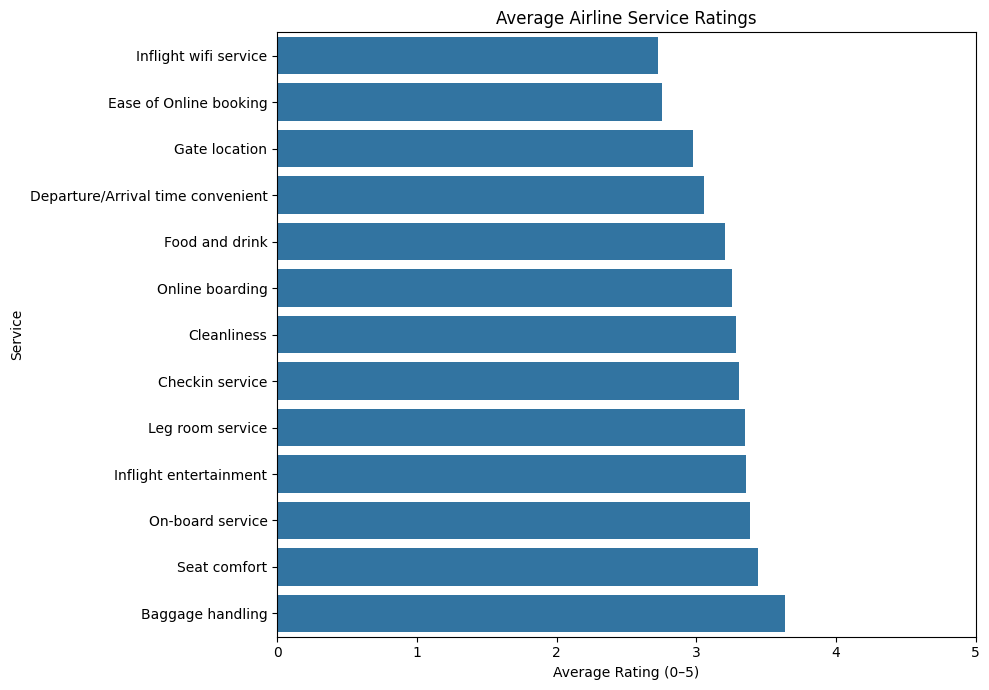

In [ ]:
plt.figure(figsize=(10, 7))

sns.barplot(
    x=service_avg.values,
    y=service_avg.index
)

plt.title("Average Airline Service Ratings")
plt.xlabel("Average Rating (0–5)")
plt.ylabel("Service")
plt.xlim(0, 5)
plt.tight_layout()
plt.show()

Inflight Wi-Fi has the lowest average rating, at approximately 2.7 out of 5.



Ease of online booking is also rated relatively low.



Gate location and departure/arrival time convenience are other areas worth investigating.



Baggage handling has the highest average rating, at approximately 3.6 out of 5.

The business question is: Are low average ratings actually linked to passenger dissatisfaction? A service may have a low average rating overall without being the strongest factor distinguishing satisfied from dissatisfied passengers.

# Compare service ratings by satisfaction

In [ ]:
# Compare service ratings by satisfaction

satisfaction_comparison = df_clean.groupby(
    "satisfaction_label"
)[rating_columns].mean().T

satisfaction_comparison["Rating Difference"] = (
    satisfaction_comparison["Satisfied"]
    - satisfaction_comparison["Not Satisfied"]
)

satisfaction_comparison = satisfaction_comparison.sort_values(
    "Rating Difference", ascending=False
)

display(satisfaction_comparison.round(2))

satisfaction_label,Not Satisfied,Satisfied,Rating Difference
Online boarding,2.66,4.03,1.37
Inflight entertainment,2.89,3.96,1.07
Seat comfort,3.04,3.97,0.93
On-board service,3.02,3.86,0.84
Leg room service,2.99,3.82,0.83
Cleanliness,2.93,3.75,0.81
Inflight wifi service,2.40,3.16,0.76
Checkin service,3.04,3.65,0.61
Baggage handling,3.37,3.97,0.59
Food and drink,2.96,3.53,0.57


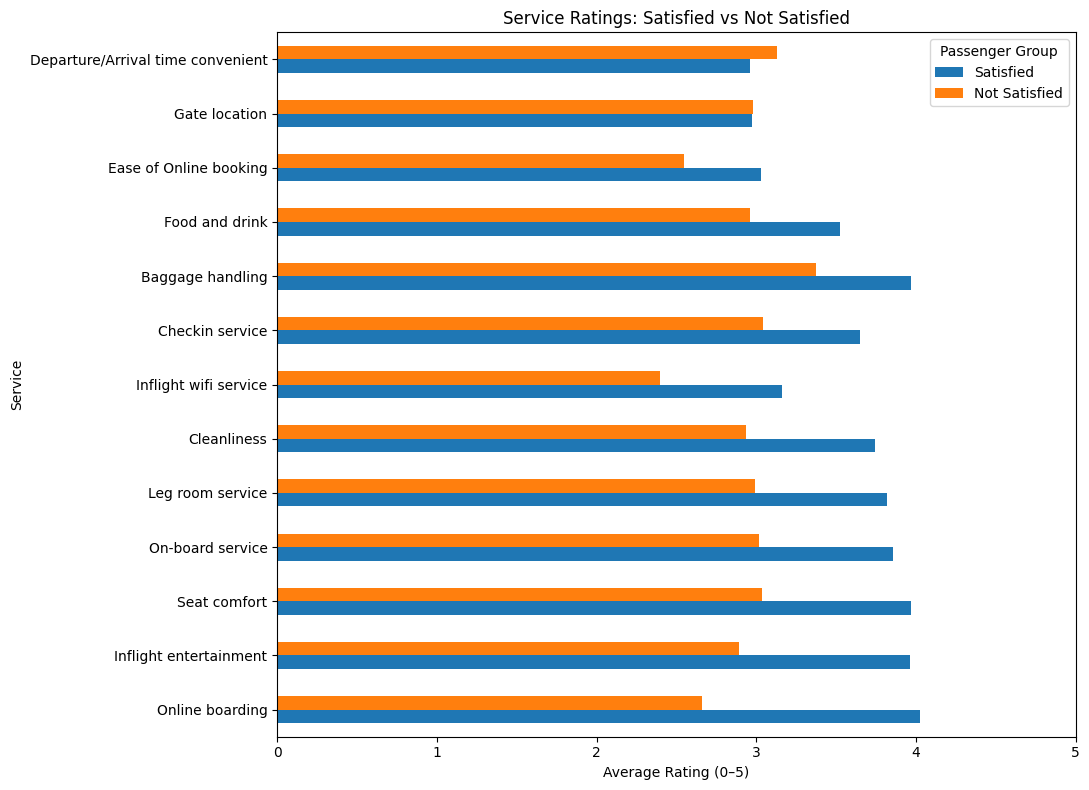

In [ ]:
satisfaction_comparison[
    ["Satisfied", "Not Satisfied"]
].plot(
    kind="barh",
    figsize=(11, 8)
)

plt.title("Service Ratings: Satisfied vs Not Satisfied")
plt.xlabel("Average Rating (0–5)")
plt.ylabel("Service")
plt.xlim(0, 5)
plt.legend(title="Passenger Group")
plt.tight_layout()
plt.show()

Online boarding shows one of the largest visible rating gaps between the two groups.



Inflight entertainment and seat comfort also show substantial differences.



Inflight Wi-Fi appears to have a noticeable gap as well.



Gate location and departure/arrival time convenience show relatively small differences compared with several other services.

This suggests that online boarding, inflight entertainment, and seat comfort deserve closer investigation. However, we should use the exact calculated differences to rank them rather than relying only on the chart.

# Find the top 5 services linked to satisfaction

In [ ]:
# Rank services by the difference in average ratings

service_ranking = satisfaction_comparison[
    ["Satisfied", "Not Satisfied", "Rating Difference"]
].sort_values(
    by="Rating Difference",
    ascending=False
)

print("Top 5 services with the largest rating differences:")
display(service_ranking.head(5).round(2))

print("Bottom 5 services with the smallest rating differences:")
display(service_ranking.tail(5).round(2))

Top 5 services with the largest rating differences:


satisfaction_label,Satisfied,Not Satisfied,Rating Difference
Online boarding,4.03,2.66,1.37
Inflight entertainment,3.96,2.89,1.07
Seat comfort,3.97,3.04,0.93
On-board service,3.86,3.02,0.84
Leg room service,3.82,2.99,0.83


Bottom 5 services with the smallest rating differences:


satisfaction_label,Satisfied,Not Satisfied,Rating Difference
Baggage handling,3.97,3.37,0.59
Food and drink,3.53,2.96,0.57
Ease of Online booking,3.03,2.55,0.48
Gate location,2.97,2.98,-0.01
Departure/Arrival time convenient,2.96,3.13,-0.17


Online boarding has the largest rating gap: 1.37 points. It is a strong candidate for further investigation.



Inflight entertainment is the second-largest gap, at 1.07 points.



Seat comfort also separates the groups noticeably.



Gate location has almost no difference between the groups in your output.

One correction to keep in mind: the final row in your screenshot appears to show a difference of -0.17 for departure/arrival time convenience. Based on the displayed averages (2.96 and 3.13), that is correct. It means dissatisfied passengers rated this service slightly higher on average. Not every service rating follows the same pattern.

These are differences between groups, not proof that improving one service will automatically cause satisfaction to rise.

# Analyze satisfaction by travel class and customer type

Now let's answer two important business questions:
1. Which travel class has the highest passenger satisfaction?
2. Are returning customers more satisfied than first-time customers?

In [ ]:
# Satisfaction rate by travel class

class_satisfaction = (
    df_clean.groupby("Class")["satisfaction"]
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
)

print("Satisfaction rate by travel class (%):")
display(class_satisfaction)

Satisfaction rate by travel class (%):


,satisfaction
Class,
Business,69.44
Eco Plus,24.64
Eco,18.77


Business-class passengers are substantially more likely to report satisfaction than passengers in the other classes. We'll calculate the exact percentages and passenger counts before documenting the final results.

In [ ]:
# Satisfaction rate by customer type

customer_satisfaction = (
    df_clean.groupby("Customer Type")["satisfaction"]
    .mean()
    .mul(100)
    .round(2)
    .sort_values(ascending=False)
)

print("Satisfaction rate by customer type (%):")
display(customer_satisfaction)

Satisfaction rate by customer type (%):


,satisfaction
Customer Type,
Loyal Customer,47.81
disloyal Customer,23.97


Loyal customers are more likely to be satisfied in this dataset. However, loyalty status alone does not explain why passengers are satisfied, so we'll explore other factors too.

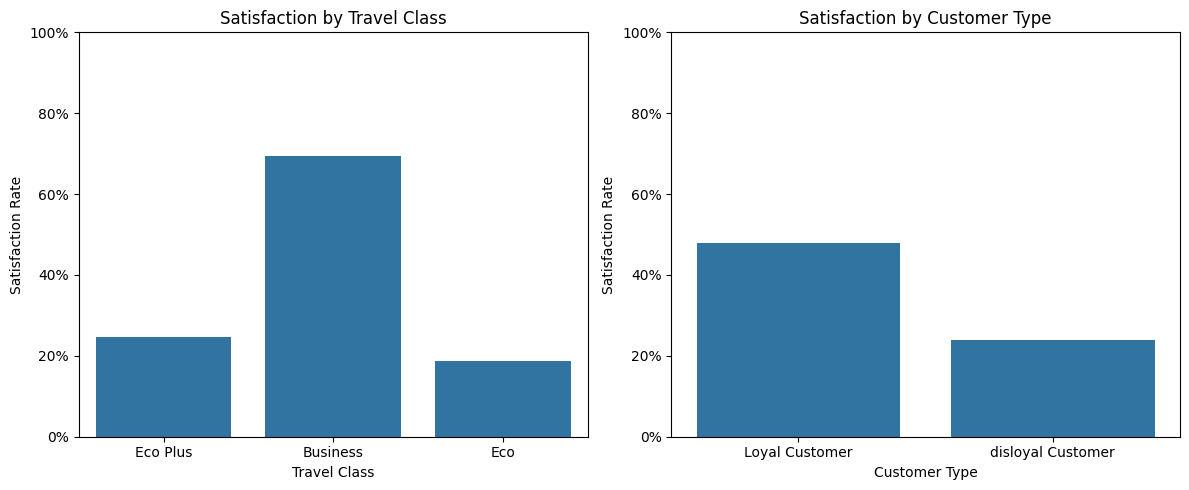

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

sns.barplot(
    data=df_clean,
    x="Class",
    y="satisfaction",
    estimator="mean",
    errorbar=None,
    ax=axes[0]
)
axes[0].set_title("Satisfaction by Travel Class")
axes[0].set_ylabel("Satisfaction Rate")
axes[0].set_xlabel("Travel Class")

sns.barplot(
    data=df_clean,
    x="Customer Type",
    y="satisfaction",
    estimator="mean",
    errorbar=None,
    ax=axes[1]
)
axes[1].set_title("Satisfaction by Customer Type")
axes[1].set_ylabel("Satisfaction Rate")
axes[1].set_xlabel("Customer Type")

for ax in axes:
    ax.set_ylim(0, 1)
    ax.yaxis.set_major_formatter(
        plt.FuncFormatter(lambda y, _: f"{y:.0%}")
    )

plt.tight_layout()
plt.show()

# Analyze flight delays and satisfaction

In [ ]:
# Compare flight delays by satisfaction group

delay_comparison = df_clean.groupby("satisfaction_label")[
    [
        "Departure Delay in Minutes",
        "Arrival Delay in Minutes"
    ]
].agg(["mean", "median", "count"])

display(delay_comparison.round(2))

Departure Delay in Minutes                \
                                         mean median  count   
satisfaction_label                                            
Not Satisfied                           16.41    0.0  73452   
Satisfied                               12.51    0.0  56428   

                   Arrival Delay in Minutes                
                                       mean median  count  
satisfaction_label                                         
Not Satisfied                         17.06    0.0  73225  
Satisfied                             12.53    0.0  56262

In [ ]:
# Create indicators for whether a flight had a delay greater than zero

df_clean["Departure Delayed"] = (
    df_clean["Departure Delay in Minutes"] > 0
)

df_clean["Arrival Delayed"] = (
    df_clean["Arrival Delay in Minutes"] > 0
)

delay_rates = df_clean.groupby("satisfaction_label")[
    ["Departure Delayed", "Arrival Delayed"]
].mean().mul(100).round(2)

print("Percentage of passengers whose flights had delays:")
display(delay_rates)

Percentage of passengers whose flights had delays:


,Departure Delayed,Arrival Delayed
satisfaction_label,,
Not Satisfied,46.01,47.60
Satisfied,40.28,38.58


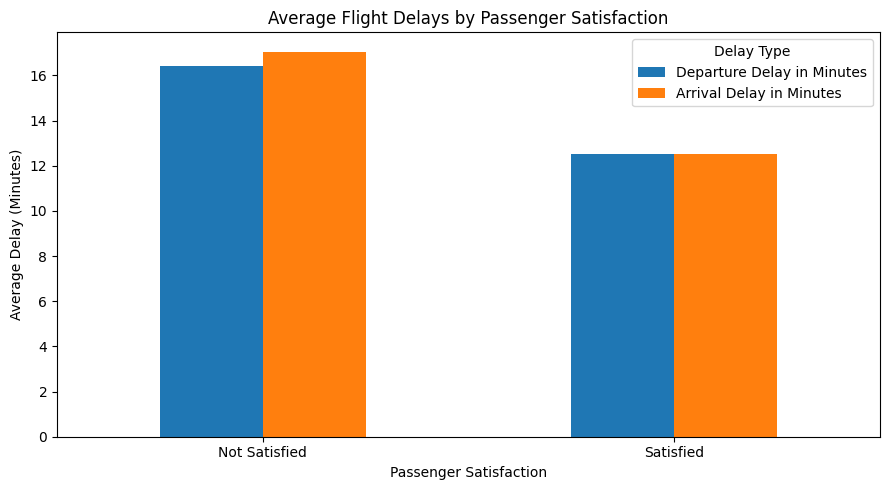

In [ ]:
# Compare average delays by satisfaction group

delay_means = df_clean.groupby("satisfaction_label")[
    [
        "Departure Delay in Minutes",
        "Arrival Delay in Minutes"
    ]
].mean()

delay_means.plot(kind="bar", figsize=(9, 5))

plt.title("Average Flight Delays by Passenger Satisfaction")
plt.xlabel("Passenger Satisfaction")
plt.ylabel("Average Delay (Minutes)")
plt.xticks(rotation=0)
plt.legend(title="Delay Type")
plt.tight_layout()
plt.show()

Not satisfied passengers: average departure delay is approximately 16.4 minutes, and arrival delay is approximately 17 minutes.



Satisfied passengers: both average departure and arrival delays are approximately 12.5 minutes.

This suggests an association between longer delays and lower passenger satisfaction. However, we should be careful: average delay alone doesn't prove that delays caused dissatisfaction, and a few very long delays can increase the average.

# Investigate delay impact more carefully

In [ ]:
# Create departure delay groups
df_clean["Departure Delay Group"] = pd.cut(
    df_clean["Departure Delay in Minutes"],
    bins=[-1, 0, 15, 60, float("inf")],
    labels=[
        "No Delay",
        "1–15 Minutes",
        "16–60 Minutes",
        "Over 60 Minutes"
    ]
)

# Calculate passenger count and satisfaction rate
delay_analysis = df_clean.groupby(
    "Departure Delay Group",
    observed=False
).agg(
    Passenger_Count=("satisfaction", "size"),
    Satisfaction_Rate=("satisfaction", "mean")
)

delay_analysis["Satisfaction_Rate"] = (
    delay_analysis["Satisfaction_Rate"] * 100
).round(2)

display(delay_analysis)

,Passenger_Count,Satisfaction_Rate
Departure Delay Group,,
No Delay,73356,45.94
1–15 Minutes,27787,43.55
16–60 Minutes,19762,37.50
Over 60 Minutes,8975,35.86


The satisfaction rate drops from 45.94% for passengers with no departure delay to 35.86% for passengers delayed by more than an hour — a difference of 10.08 percentage points.

This supports an association between longer departure delays and lower satisfaction. However, even passengers with no departure delay have a satisfaction rate below 50%, suggesting that service quality and other factors also matter.

# **Prepare the final dataset for Power BI**

In [ ]:
# Create the final dataset for Power BI
powerbi_df = df_clean.copy()

# Add a readable satisfaction label if not already present
powerbi_df["satisfaction_label"] = powerbi_df["satisfaction"].map({
    True: "Satisfied",
    False: "Not Satisfied"
})

# Add departure delay groups
powerbi_df["Departure Delay Group"] = pd.cut(
    powerbi_df["Departure Delay in Minutes"],
    bins=[-1, 0, 15, 60, float("inf")],
    labels=[
        "No Delay",
        "1–15 Minutes",
        "16–60 Minutes",
        "Over 60 Minutes"
    ]
)

# Export final dataset
output_file = "/content/airline_satisfaction_powerbi.csv"

powerbi_df.to_csv(output_file, index=False)

print("Final dataset shape:", powerbi_df.shape)
print("Missing arrival delays:",
      powerbi_df["Arrival Delay in Minutes"].isna().sum())
print("File ready for Power BI:", output_file)

Final dataset shape: (129880, 26)
Missing arrival delays: 393
File ready for Power BI: /content/airline_satisfaction_powerbi.csv


In [ ]:
from google.colab import files

files.download("/content/airline_satisfaction_powerbi.csv")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>